# 01 — Cartpole: Lagrange ile hareket denklemleri + simülasyon

Açıklamalar: **`NOTLAR_Asama1_2.md` → Bölüm 1–4.** Bu defter o notların hesap tarafı.

Kural: θ = 0 yukarı, θ > 0 sağa; x > 0 sağ; F > 0 sağa. Noktasal kütle m, kütlesiz çubuk l, araba M, sürtünme yok.

| bölüm | ne yapıyoruz |
|---|---|
| A | sympy ile türetme: konum → T, V → L → Euler–Lagrange → ẍ, θ̈ → E |
| B | Ek A.1 ve `cartpole.py` ile karşılaştırma |
| C | Önce simüle et: yukarıdan / aşağıdan bırakma, animasyon |
| D | Entegratör: Euler vs RK4, enerji, dt seçimi |

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / 'cartpole.py').exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, HTML
sp.init_printing()
plt.rcParams['figure.dpi'] = 90

import cartpole as cp
P = cp.CartPoleParams()
fn = cp.make_f(P)
ZERO = lambda t, s: 0.0

---
## A1. Semboller, genelleştirilmiş koordinatlar
`sp.Function('x')(t)` → x zamana bağlı (türevi alınabilir). Düz `symbols` deseydik türevi 0 olurdu.

In [2]:
t = sp.symbols('t')
M, m, l, g = sp.symbols('M m l g', positive=True)
F = sp.symbols('F', real=True)
x  = sp.Function('x')(t)
th = sp.Function('theta')(t)
q, qd = [x, th], [x.diff(t), th.diff(t)]

## A2. Sarkaç kütlesinin konumu ve hızı
θ dikeyden ölçülüyor → yatay **l sinθ**, düşey **l cosθ**. Hız = zincir kuralı: d/dt sinθ = cosθ·θ̇.

In [3]:
xp = x + l*sp.sin(th)
yp = l*sp.cos(th)
display(xp.diff(t), yp.diff(t))

## A3. Enerjiler ve Lagrangian
T = ½Mẋ² + ½m(ẋ_p² + ẏ_p²),  V = m g y_p,  L = T − V.
Beklenen: T = ½(M+m)ẋ² + **m l ẋ θ̇ cosθ** (bağlaşım) + ½ m l² θ̇²

In [4]:
T = sp.Rational(1, 2)*M*x.diff(t)**2 + sp.Rational(1, 2)*m*(xp.diff(t)**2 + yp.diff(t)**2)
V = m*g*yp
L = T - V
display(sp.expand(sp.simplify(T)), V)

## A4. Euler–Lagrange:  d/dt(∂L/∂q̇) − ∂L/∂q = Q,   Q = [F, 0]
Önce "momentumlara" bakalım: ∂L/∂ẋ = M ẋ + m ẋ_p → **sistemin toplam yatay momentumu**.

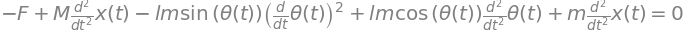

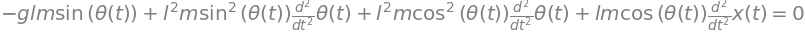

In [5]:
p_x  = sp.simplify(L.diff(qd[0]))
p_th = sp.simplify(L.diff(qd[1]))
display(p_x, p_th)

Q = [F, 0]
EL = [sp.expand(L.diff(qdi).diff(t) - L.diff(qi) - Qi) for qi, qdi, Qi in zip(q, qd, Q)]
for e in EL:
    display(sp.Eq(e, 0))

Türevleri düz sembollere çevir (sıra önemli: önce 2. türevler). Sonra **kütle matrisi** biçimi: M(q) q̈ = b.
M(q) simetrik, det = m l²(M + m sin²θ) > 0 → her θ'da tersinir → ẍ, θ̈ her zaman tek türlü bulunur.

In [6]:
xs, xd, xdd, ths, thd, thdd = sp.symbols('x xdot xddot theta thetadot thetaddot', real=True)
def S(e):
    for a, b in [(x.diff(t, 2), xdd), (th.diff(t, 2), thdd), (x.diff(t), xd), (th.diff(t), thd), (x, xs), (th, ths)]:
        e = e.subs(a, b)
    return e
eqs = [S(e) for e in EL]
Mq, b = sp.linear_eq_to_matrix(eqs, [xdd, thdd])
display(sp.simplify(Mq), sp.simplify(b), sp.factor(Mq.det()))

⎡  M + m     l⋅m⋅cos(θ)⎤
⎢                      ⎥
⎢                2     ⎥
⎣l⋅m⋅cos(θ)     l ⋅m   ⎦

⎡         2       ⎤
⎢F + l⋅m⋅θ̇ ⋅sin(θ)⎥
⎢                 ⎥
⎣  g⋅l⋅m⋅sin(θ)   ⎦

## A5. ẍ ve θ̈ için çöz → ṡ = f(s, F)

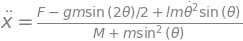

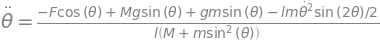

In [7]:
sol = sp.solve(eqs, [xdd, thdd], dict=True)[0]
xdd_e, thdd_e = sp.simplify(sol[xdd]), sp.simplify(sol[thdd])
display(sp.Eq(xdd, xdd_e), sp.Eq(thdd, thdd_e))
E_e = sp.simplify(S(T + V))
display(E_e)

---
## B1. 🔍 Ek A.1 ile sembolik karşılaştırma

In [8]:
den = M + m*sp.sin(ths)**2
ref = {'xdd':  (F + m*sp.sin(ths)*(l*thd**2 - g*sp.cos(ths))) / den,
       'thdd': (-F*sp.cos(ths) - m*l*thd**2*sp.sin(ths)*sp.cos(ths) + (M + m)*g*sp.sin(ths)) / (l*den),
       'E':    (M + m)*xd**2/2 + m*l*xd*thd*sp.cos(ths) + m*l**2*thd**2/2 + m*g*l*sp.cos(ths)}
mine = {'xdd': xdd_e, 'thdd': thdd_e, 'E': E_e}
for k in ref:
    print(f'{k:5s} simplify(senin − referans) =', sp.simplify(mine[k] - ref[k]))

xdd   simplify(senin − referans) = 0
thdd  simplify(senin − referans) = 0
E     simplify(senin − referans) = 0


## B2. `lambdify` → numpy, `cartpole.py` ile 100 rastgele durumda karşılaştırma

In [9]:
f_np = sp.lambdify([xd, ths, thd, F, M, m, l, g], (xdd_e, thdd_e), 'numpy')
E_np = sp.lambdify([xd, ths, thd, M, m, l, g], E_e, 'numpy')
rng = np.random.default_rng(0)
ef = eE = 0.0
for _ in range(100):
    s = rng.uniform([-2, -3, -np.pi, -6], [2, 3, np.pi, 6]); u = rng.uniform(-10, 10)
    ef = max(ef, np.abs(np.array(f_np(s[1], s[2], s[3], u, P.M, P.m, P.l, P.g)) - cp.f(s, u, P)[[1, 3]]).max())
    eE = max(eE, abs(E_np(s[1], s[2], s[3], P.M, P.m, P.l, P.g) - cp.energy(s, P)))
print(f'max |f_sympy − f_kod| = {ef:.1e}    max |E_sympy − E_kod| = {eE:.1e}')

max |f_sympy − f_kod| = 7.1e-15    max |E_sympy − E_kod| = 8.9e-16


---
## C1. 👀 Önce simüle et: yukarıya yakın ve aşağıya yakın bırak (F = 0)
Tahmin et, sonra bak:
- θ₀ = 0.1: sarkaç düşer, **araba ters yöne** kayar (yatay momentum korunumu: M ẋ + m ẋ_p = 0).
- θ₀ = π + 0.1: aşağıda salınır; periyot ≈ 2π/√((M+m)g/(Ml)) ≈ 1.35 s.

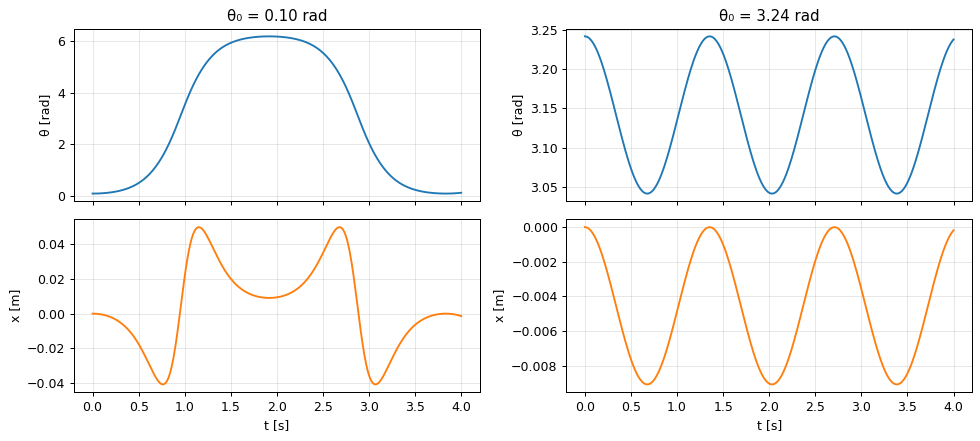

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(11, 5), sharex=True)
for j, th0 in enumerate([0.1, np.pi + 0.1]):
    tt, SS, _ = cp.simulate(fn, [0, 0, th0, 0], ZERO, 0.01, 4.0)
    ax[0, j].plot(tt, SS[:, 2]); ax[0, j].set_title(f'θ₀ = {th0:.2f} rad'); ax[0, j].set_ylabel('θ [rad]')
    ax[1, j].plot(tt, SS[:, 0], color='tab:orange'); ax[1, j].set_ylabel('x [m]'); ax[1, j].set_xlabel('t [s]')
for a in ax.flat: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## C2. Animasyon: serbest düşüş, θ₀ = 0.3 rad (canlı pencere için: `python cartpole.py 0.3`)

In [5]:
tt, SS, UU = cp.simulate(fn, [0, 0, 0.3, 0], ZERO, 0.02, 4.0)
HTML(cp.animate(tt, SS, P, U=UU, fps=20, show=False).to_jshtml())

## C3. Fiziksel sezgi: sabit F = 5 N, dik başlangıç
Araba sağa ivmelenir, sarkaç **sola** yatar (B'deki −1/(Ml): F > 0 → θ̈ < 0).

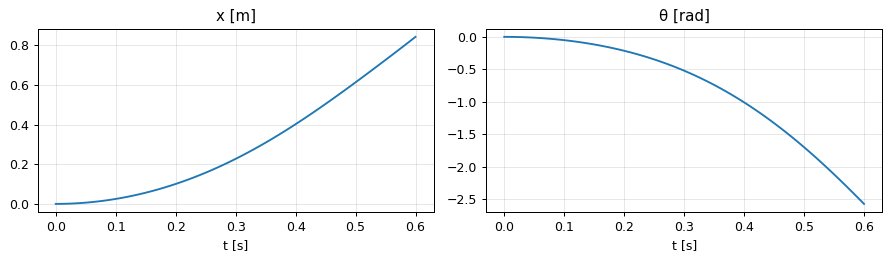

In [12]:
tt, SS, UU = cp.simulate(fn, [0, 0, 0, 0], lambda t, s: 5.0, 0.01, 0.6)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(tt, SS[:, 0]); ax[0].set(title='x [m]', xlabel='t [s]')
ax[1].plot(tt, SS[:, 2]); ax[1].set(title='θ [rad]', xlabel='t [s]')
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

---
## D1. Euler vs RK4: enerji kayması (F = 0, θ₀ = 0.3, 10 s)
Sürtünme yok → **E sabit kalmalı**. Kalmıyorsa hata modelde değil entegratörde.

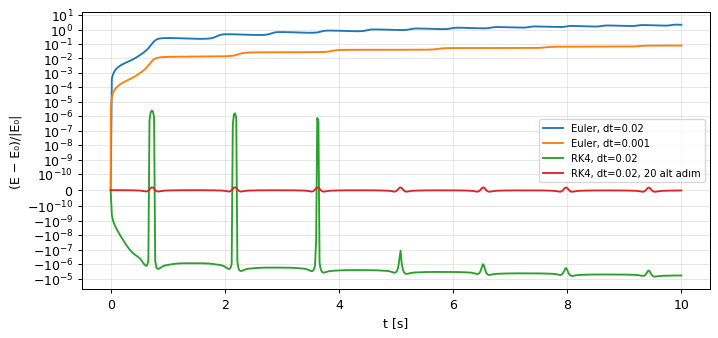

Euler, dt=0.02               max |ΔE/E₀| = 2.2e+00
Euler, dt=0.001              max |ΔE/E₀| = 7.8e-02
RK4, dt=0.02                 max |ΔE/E₀| = 7.4e-06
RK4, dt=0.02, 20 alt adım    max |ΔE/E₀| = 1.8e-11


In [13]:
def drift(S):
    E = np.array([cp.energy(s, P) for s in S]); return (E - E[0]) / abs(E[0])

fig, ax = plt.subplots(figsize=(9, 4))
rows = []
for name, step, dt, sub in [('Euler', cp.euler_step, 0.02, 1), ('Euler', cp.euler_step, 0.001, 1),
                            ('RK4', cp.rk4_step, 0.02, 1), ('RK4', cp.rk4_step, 0.02, 20)]:
    tt, SS, _ = cp.simulate(fn, [0, 0, 0.3, 0], ZERO, dt, 10.0, step=step, substeps=sub)
    d = drift(SS)
    lbl = f'{name}, dt={dt}' + (f', {sub} alt adım' if sub > 1 else '')
    ax.plot(tt, d, label=lbl); rows.append((lbl, np.abs(d).max()))
ax.set_yscale('symlog', linthresh=1e-10); ax.set(xlabel='t [s]', ylabel='(E − E₀)/|E₀|'); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.show()
for lbl, v in rows: print(f'{lbl:28s} max |ΔE/E₀| = {v:.1e}')

**Okuma:** Euler enerjiyi sistematik olarak **artırıyor** (dt = 0.02'de %200+). RK4 dt = 0.02'de 7e-6:
sıçramalar sarkacın en alttan **en hızlı** geçtiği anlarda. Hedef < 1e-6 → kontrol adımı dt = 0.02 kalır,
fizik 20 alt adımla (h = 0.001) entegre edilir (`substeps=20`). Karar: KARARLAR.md.

## D2. Adım boyu: RK4 dt = 0.02 ile dt = 0.001 aynı yörüngeyi veriyor mu?

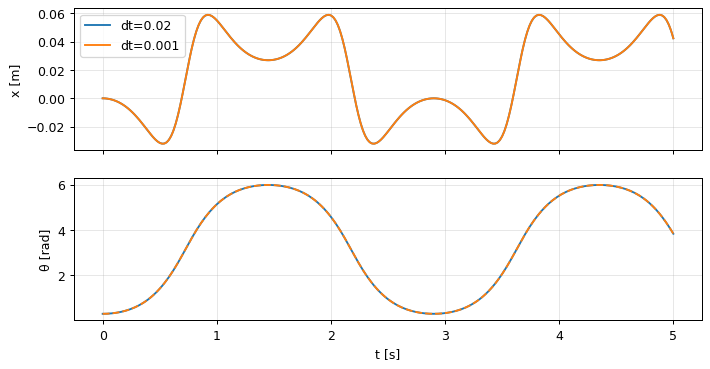

5 s boyunca max fark [x, ẋ, θ, θ̇] = [7.00e-06 6.10e-05 1.85e-04 4.33e-04]


In [14]:
fig, ax = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
res = {}
for dt in (0.02, 0.001):
    tt, SS, _ = cp.simulate(fn, [0, 0, 0.3, 0], ZERO, dt, 5.0); res[dt] = SS
    ax[0].plot(tt, SS[:, 0], label=f'dt={dt}'); ax[1].plot(tt, SS[:, 2], '--' if dt < 0.01 else '-', label=f'dt={dt}')
ax[0].set_ylabel('x [m]'); ax[1].set(ylabel='θ [rad]', xlabel='t [s]'); ax[0].legend()
for a in ax: a.grid(alpha=.3)
plt.show()
err = np.abs(res[0.02] - res[0.001][::20]).max(axis=0)
print('5 s boyunca max fark [x, ẋ, θ, θ̇] =', np.round(err, 6))